# HelpDesk Analytics · Análisis avanzado

**Notebook 02 | Distribuciones · Cohortes · Reaperturas · Estados · Sensibilidad**

Un análisis estadístico descriptivo con definiciones explícitas, resultados conciliados y límites de interpretación.

Las tablas y los siete gráficos se calculan desde los CSV procesados. Reinicia el kernel de **`.venv`** y ejecuta todas las celdas en orden. No se requiere acceso a SQL Server ni al dashboard; no se ejecuta la limpieza ni se modifican datos. Se conservan salidas agregadas para GitHub, sin registros individuales.

## 1. Introducción

### Objetivo y preguntas de investigación

Profundizar en la forma de las distribuciones y en la sensibilidad de los indicadores, sin repetir la exploración general del [notebook 01](01_exploratory_analysis.ipynb).

1. ¿Cómo se distribuye el tiempo **calendario** hasta la resolución registrada y cuánto difieren su mediana y P90?
2. ¿Qué cambia al seleccionar creaciones desde 2016 o comparar cohortes de distintos años?
3. ¿Qué diferencias descriptivas existen entre prioridades y tipos de ticket?
4. ¿Coinciden las visitas agregadas a `reopened` con los eventos históricos? ¿Qué explica aritméticamente sus diferencias?
5. ¿Qué estados acumulan más duración típica y cuáles fueron recorridos por más tickets?
6. ¿Cómo cambian los resultados al aplicar filtros de calidad, y cuántos registros se excluyen?

### Fuente y alcance

**Mohammad Abdellatif, *Help Desk Tickets*, versión 3**, Mendeley Data, [DOI 10.17632/btm76zndnt.3](https://doi.org/10.17632/btm76zndnt.3), licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). La atribución se conserva en [README](../README.md#fuente-de-datos-y-atribución).

Las definiciones del proveedor están en [FEATURES.md](../data/FEATURES.md). Las referencias del proyecto son [el análisis SQL avanzado](../reports/sql_advanced_analysis.md), [sus consultas](../sql/04_advanced_analysis.sql), [calidad de datos](../reports/data_quality.md) y [el informe final](../reports/final_analysis.md).

Se estudia una extracción histórica con tipos de registro heterogéneos. Los tickets comienzan en 2007 y los eventos en 2015, aunque la documentación describe tickets desde 2016. Tener algún evento no garantiza una historia completa. Los resultados son descriptivos: no prueban causas, mejoras operativas, satisfacción ni cumplimiento de SLA.

## 2. Preparación

### Librerías, estilo y presentación

Se reutiliza la paleta del primer notebook: azul para indicadores, verde azulado para comparación y naranja para advertencias, `unknown` y períodos parciales. Las cifras de las tablas usan formato español. Los cálculos mantienen su precisión y sólo se redondean al presentar.

In [1]:
from pathlib import Path
from decimal import Decimal, localcontext
import hashlib
import re
import sys

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import SymLogNorm, LinearSegmentedColormap
from IPython.display import HTML, Markdown, display

PALETA = {"azul": "#245C83", "verde": "#168477", "naranja": "#BA6515",
          "gris": "#77838F", "texto": "#203341", "rejilla": "#E2E8ED"}
mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 13,
    "axes.titleweight": "bold", "text.color": PALETA["texto"],
    "axes.labelcolor": PALETA["texto"], "axes.spines.top": False,
    "axes.spines.right": False, "axes.spines.left": False,
    "axes.spines.bottom": False, "axes.axisbelow": True,
    "grid.color": PALETA["rejilla"], "grid.linewidth": 0.7,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "figure.dpi": 110, "savefig.dpi": 125, "savefig.bbox": "tight",
})
pd.set_option("display.max_rows", 20)
pd.set_option("display.max_columns", 9)

def numero_es(valor, decimales=0):
    return f"{valor:,.{decimales}f}".translate(str.maketrans({",": ".", ".": ","}))

def mostrar(tabla, decimales=2):
    if len(tabla) > 20 or len(tabla.columns) > 9:
        raise ValueError("Selecciona explícitamente una tabla agregada de tamaño publicable.")
    formatos = {c: (lambda x: numero_es(x, decimales))
                for c in tabla.select_dtypes(include="floating").columns}
    formatos.update({c: (lambda x: numero_es(x))
                     for c in tabla.select_dtypes(include="integer").columns})
    display(HTML(tabla.to_html(index=False, border=0, na_rep="—", formatters=formatos)))

def eje_numerico(ax, eje="x", decimales=0):
    getattr(ax, f"{eje}axis").set_major_formatter(
        FuncFormatter(lambda v, _: numero_es(v, decimales)))

mostrar(pd.DataFrame({"Herramienta": ["Python", "Pandas", "NumPy", "Matplotlib"],
                     "Versión": [sys.version.split()[0], pd.__version__, np.__version__, mpl.__version__]}))

Herramienta,Versión
Python,3.13.2
Pandas,2.3.3
NumPy,2.5.4
Matplotlib,3.11.2


### Rutas, carga y contrato de datos

La raíz se resuelve recorriendo el directorio actual y sus padres. Se reutiliza `read_csv` del proyecto: sólo los campos vacíos representan nulos; `unknown` se conserva como texto. Las conversiones de fechas y números son analíticas y se hacen únicamente en memoria. No se llama al ETL.

Se comprueban dimensiones, columnas, claves y fechas frente a las referencias. Los IDs sólo se utilizan internamente para enlazar y contrastar; no se muestran. Las huellas SHA-256 controlan los dos CSV procesados y los informes usados como evidencia durante la ejecución.

In [2]:
def encontrar_raiz(inicio):
    for candidato in [inicio, *inicio.parents]:
        if ((candidato / "src/clean_data.py").is_file()
                and (candidato / "reports/sql_advanced_analysis.md").is_file()):
            return candidato
    raise FileNotFoundError("Abre el notebook dentro del proyecto HelpDesk Analytics.")

RAIZ = encontrar_raiz(Path.cwd().resolve())
if Path(sys.prefix).resolve() != (RAIZ / ".venv").resolve():
    raise RuntimeError("Selecciona el kernel del entorno .venv de este proyecto.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
from src.clean_data import read_csv

RUTAS = {"Tickets": RAIZ / "data/processed/issues_clean.csv",
         "Eventos": RAIZ / "data/processed/issues_change_history_clean.csv"}
REFERENCIAS = [RAIZ / f"reports/{nombre}" for nombre in
               ["sql_advanced_analysis.md", "data_quality.md", "final_analysis.md"]]
for ruta in [*RUTAS.values(), *REFERENCIAS, RAIZ / "data/FEATURES.md"]:
    if not ruta.is_file():
        raise FileNotFoundError(f"Falta el archivo del proyecto {ruta.name}.")

def huella(ruta):
    with ruta.open("rb") as archivo:
        return hashlib.file_digest(archivo, "sha256").hexdigest()

protegidos = [*RUTAS.values(), *REFERENCIAS]
huellas_antes = {ruta: huella(ruta) for ruta in protegidos}
t = read_csv(RUTAS["Tickets"])
e = read_csv(RUTAS["Eventos"])
ESTADOS = [c[3:] for c in t if c.startswith("wf_") and c != "wf_total_time"]
requeridas = {"id", "issue_priority", "issue_type", "issue_resolution", "issue_created",
              "issue_resolution_date", "last_change_date", "wfe_reopened", "dq_has_problem",
              "dq_negative_duration", "dq_duration_mismatch"}
if not requeridas.issubset(t.columns) or not {"id", "issueid", "field", "value", "created"}.issubset(e.columns):
    raise ValueError("El esquema no contiene las columnas necesarias para el análisis.")
if any(f"wfe_{estado}" not in t for estado in ESTADOS):
    raise ValueError("Cada duración por estado debe tener su contador de visitas.")

mostrar(pd.DataFrame([
    {"Dataset": "Tickets", "Filas": len(t), "Columnas": t.shape[1]},
    {"Dataset": "Eventos", "Filas": len(e), "Columnas": e.shape[1]},
]))

Dataset,Filas,Columnas
Tickets,66.691,102
Eventos,257.508,28


### Validación estadística y referencias SQL

Se leen las tablas del informe avanzado, sin ejecutar SQL ni importar el ejecutor de consultas. Los **conteos se exigen exactos**; las sumas de duración se comparan con `Decimal` exacto. Para los percentiles SQL aproximados se usan las tolerancias del proyecto: absoluta de 0,0001 en la unidad de salida y relativa de 10⁻¹². Los nulos se comparan explícitamente.

El cálculo principal utiliza agregaciones de Pandas. Las medianas y P90 se verifican además agrupando los valores originales y llamando a `Series.quantile`, y se contrastan con `NumPy.quantile(method='linear')`. Un fallo detiene la ejecución con un mensaje de control, sin publicar IDs ni ajustar la referencia.

In [3]:
controles = []

def verificar(nombre, condicion, alcance):
    if not bool(condicion):
        raise AssertionError(f"Discrepancia en {nombre}; investiga la definición y la referencia.")
    controles.append({"Control": nombre, "Estado": "SUPERADA", "Alcance": alcance})

def tabla_sql(seccion):
    texto = REFERENCIAS[0].read_text(encoding="utf-8")
    bloque = re.search(rf"^## {re.escape(seccion)}\. [^\n]*\n(.*?)(?=^## |\Z)",
                      texto, flags=re.M | re.S)
    if bloque is None:
        raise ValueError("Sección SQL no encontrada.")
    filas = []
    for linea in bloque.group(1).splitlines():
        if linea.startswith("|"):
            filas.append([v.strip() for v in linea.strip("|").split("|")])
        elif filas:
            break
    return pd.DataFrame(filas[2:], columns=filas[0])

CONTEOS = set("poblacion elegibles excluidos tickets cohorte done_elegibles no_elegibles_done "
              "sin_fecha_resolucion periodo_parcial dias_desde_fin_periodo con_historial agregado_null "
              "tickets_wfe_reopened visitas_agregadas tickets_evento_reopened eventos_reopened comparables "
              "discrepantes wfe_reopened eventos_total observados nulos positivos ceros negativos "
              "elegibles_por_visita duracion_sin_visitas_validas elegibles_calendario elegibles_done "
              "offset_no_utc fraccion_submicrosegundo".split())
FECHAS = {"creacion_min", "historial_min", "corte_observado", "creacion_utc", "resolucion_utc"}
SUMAS_EXACTAS = {"suma_firmada_seg", "suma_positiva_seg", "wf_total_seg"}

def conciliar(seccion, observado, claves):
    esperado = tabla_sql(seccion)
    if set(observado.columns) != set(esperado.columns):
        raise ValueError(f"Columnas incompatibles en la sección {seccion}.")
    observado = observado.copy()
    for clave in claves:
        observado[clave] = observado[clave].astype(str)
        esperado[clave] = esperado[clave].astype(str)
    a = observado.set_index(claves).sort_index()
    b = esperado.set_index(claves).sort_index()
    verificar(f"SQL {seccion}: grupos", a.index.equals(b.index) and a.index.is_unique,
              f"{len(a)} grupos; sin publicar claves individuales")
    for columna in a:
        x = a[columna]
        y = b[columna].replace("(NULL)", pd.NA)
        if columna in FECHAS:
            coincide = pd.to_datetime(x, utc=True).equals(pd.to_datetime(y, utc=True))
        elif columna in SUMAS_EXACTAS:
            convertir = lambda v: None if pd.isna(v) else Decimal(str(v))
            coincide = x.map(convertir).tolist() == y.map(convertir).tolist()
        elif columna in CONTEOS or columna == "id":
            coincide = x.map(int).tolist() == y.map(int).tolist()
        elif columna.startswith("dq_") or columna in {"grupo", "issue_priority", "issue_type", "cobertura", "motivo"}:
            coincide = x.astype(str).tolist() == y.astype(str).tolist()
        else:
            xx = pd.to_numeric(x, errors="raise").to_numpy(dtype=float, na_value=np.nan)
            yy = pd.to_numeric(y, errors="raise").to_numpy(dtype=float, na_value=np.nan)
            coincide = np.allclose(xx, yy, atol=0.0001, rtol=1e-12, equal_nan=True)
        if not coincide:
            raise AssertionError(f"Discrepancia SQL {seccion}, campo {columna}; no se publican valores individuales.")
    verificar(f"SQL {seccion}: métricas", True, f"{len(a.columns)} campos en todos los grupos")

def resumen_tiempos(datos, claves, valor="segundos"):
    agrupado = datos.groupby(claves, dropna=False, observed=True)[valor]
    r = agrupado.agg(poblacion="size", elegibles="count", mediana_seg="median")
    r["p90_seg"] = agrupado.quantile(0.9, interpolation="linear")
    r["excluidos"] = r["poblacion"] - r["elegibles"]
    r["mediana_dias"] = r["mediana_seg"] / 86400
    r["p90_dias"] = r["p90_seg"] / 86400
    return r.reset_index()[claves + ["poblacion", "elegibles", "excluidos", "mediana_seg",
                                    "p90_seg", "mediana_dias", "p90_dias"]]

def validar_cuantiles(datos, claves, resumen, valor="segundos",
                      mediana="mediana_seg", p90="p90_seg", nombre="Cuantiles"):
    indice = resumen.set_index(claves)
    contador = 0
    for clave, grupo in datos.groupby(claves, dropna=False, observed=True):
        if len(claves) == 1 and isinstance(clave, tuple):
            clave = clave[0]
        s = pd.to_numeric(grupo[valor].dropna(), errors="raise").astype(float).sort_values()
        pandas_independiente = s.quantile([0.5, 0.9], interpolation="linear").to_numpy()
        numpy_independiente = np.quantile(s.to_numpy(), [0.5, 0.9], method="linear") if len(s) else np.array([np.nan, np.nan])
        obtenido = indice.loc[clave, [mediana, p90]].to_numpy(dtype=float)
        if not (np.allclose(obtenido, pandas_independiente, atol=0.0001, rtol=1e-12, equal_nan=True)
                and np.allclose(obtenido, numpy_independiente, atol=0.0001, rtol=1e-12, equal_nan=True)):
            raise AssertionError(f"Discrepancia en {nombre}; revisar población elegible.")
        contador += 1
    verificar(nombre, True, f"{contador} grupos; agregación, Series.quantile y NumPy")

verificar("Claves", t.id.notna().all() and t.id.is_unique and e.id.notna().all()
          and e.id.is_unique and e.issueid.isin(t.id).all(), "IDs no nulos, únicos; historial sin huérfanos")
ref_s = tabla_sql("S").iloc[0]
verificar("Dimensiones", len(t) == int(ref_s.tickets) and t.shape[1] == 102 and e.shape == (257508, 28),
          "Contrato documentado: 66.691 × 102 y 257.508 × 28")

## 3. Tiempos de resolución

### Definición, elegibilidad y denominadores

**Tiempo calendario = fecha de resolución − fecha de creación**, dividido entre 86.400 segundos por día. Incluye noches, fines de semana y pausas. No es `wf_total_time` ni tiempo trabajado.

Un ticket es elegible si tiene etiqueta de resolución y ambas fechas, y la resolución no precede a la creación. Se separan `Done`, otras resoluciones y ausencia de resolución. No se excluyen flags de calidad por defecto. Los motivos de exclusión se asignan en orden y son mutuamente excluyentes.

La mediana divide la distribución observada en dos mitades. El P90 es un cuantil interpolado: puede no corresponder a un ticket concreto y no es un compromiso de servicio. Una única fecha almacenada tampoco permite identificar primera resolución o resolución definitiva tras reaperturas.

In [4]:
b = t[["id", "issue_priority", "issue_type", "issue_resolution"]].copy()
b = b.rename(columns={"issue_priority": "prioridad", "issue_type": "tipo"})
for origen, destino in [("issue_created", "creacion"), ("issue_resolution_date", "resolucion"),
                         ("last_change_date", "ultimo_cambio")]:
    b[destino] = pd.to_datetime(t[origen], utc=True, format="ISO8601", errors="raise")
fechas_eventos = pd.to_datetime(e.created, utc=True, format="ISO8601", errors="raise")
b["grupo"] = np.select([t.issue_resolution.eq("Done").fillna(False).to_numpy(dtype=bool),
                         t.issue_resolution.isna().to_numpy()], ["Done", "Sin resolución"],
                        default="Otras resoluciones")
b["motivo"] = np.select([
    t.issue_resolution.isna().to_numpy(),
    (b.creacion.isna() | b.resolucion.isna()).to_numpy(),
    b.resolucion.lt(b.creacion).to_numpy()],
    ["sin_resolucion", "sin_fechas", "orden_negativo"], default="elegible")
b["segundos"] = (b.resolucion - b.creacion).dt.total_seconds().where(b.motivo.eq("elegible"))
b["dias"] = b.segundos / 86400
b["segundos_done"] = b.segundos.where(b.grupo.eq("Done"))
inicio = b.creacion.min()
inicio_historial = fechas_eventos.min()
corte = max(b.creacion.max(), b.resolucion.max(), b.ultimo_cambio.max(), fechas_eventos.max())
offsets_originales = pd.DataFrame({campo: t[campo].map(
    lambda v: False if pd.isna(v) else pd.Timestamp(v).utcoffset() != pd.Timedelta(0))
    for campo in ["issue_created", "issue_resolution_date"]})
submicrosegundo = b.creacion.dt.nanosecond.fillna(0).ne(0) | b.resolucion.dt.nanosecond.fillna(0).ne(0)
auditoria = pd.DataFrame([{
    "tickets": len(t), "offset_no_utc": int(offsets_originales.any(axis=1).sum()),
    "fraccion_submicrosegundo": int(submicrosegundo.sum()),
    "creacion_min": inicio, "historial_min": inicio_historial, "corte_observado": corte,
}])
conciliar("S", auditoria, ["tickets"])
resoluciones = resumen_tiempos(b, ["grupo"])
conciliar("A", resoluciones, ["grupo"])
validar_cuantiles(b, ["grupo"], resoluciones, nombre="Resoluciones: cuantiles independientes")
exclusiones = b.groupby(["grupo", "motivo"], dropna=False).size().reset_index(name="tickets")
conciliar("A_EXCLUSIONES", exclusiones, ["grupo", "motivo"])
mostrar(resoluciones[["grupo", "poblacion", "elegibles", "excluidos", "mediana_dias", "p90_dias"]]
        .rename(columns={"grupo": "Resolución", "poblacion": "Población", "elegibles": "Elegibles",
                         "excluidos": "Excluidos", "mediana_dias": "Mediana (días)", "p90_dias": "P90 (días)"}))
mostrar(exclusiones.rename(columns={"grupo": "Resolución", "motivo": "Motivo", "tickets": "Tickets"}))

Resolución,Población,Elegibles,Excluidos,Mediana (días),P90 (días)
Done,62.034,62.034,0,"35,87","2.858,35"
Otras resoluciones,3.804,3.804,0,"24,02","629,18"
Sin resolución,853,0,853,—,—


Resolución,Motivo,Tickets
Done,elegible,62.034
Otras resoluciones,elegible,3.804
Sin resolución,sin_resolucion,853


### Histogramas y valores extremos

Se utiliza el **rango completo** de ambas distribuciones elegibles, con intervalos lineales de igual ancho y los mismos bordes. Cada panel tiene su propio eje de frecuencia, claramente rotulado. No se recortan colas, no se winsorizan valores ni se aplican filtros de calidad.

Las líneas señalan mediana y P90. La escala amplia puede comprimir visualmente los tiempos cortos: es parte de la asimetría y no justifica ocultar registros. Las alturas son tickets por intervalo, no densidades ni horas de trabajo.

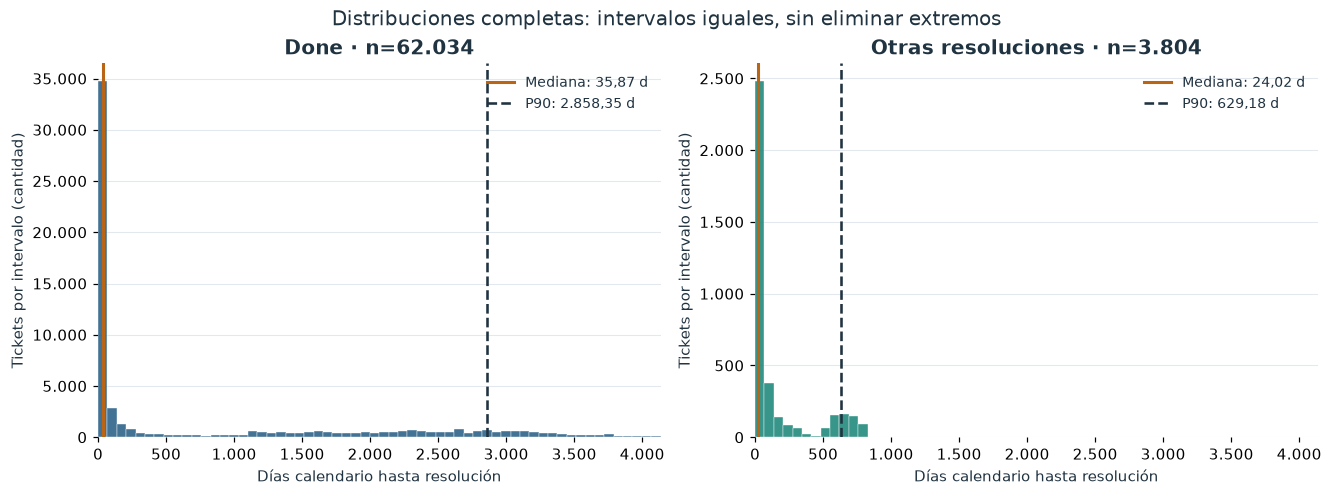

In [5]:
maximo_dias = float(b.dias.max())
bordes = np.linspace(0, np.ceil(maximo_dias), 61)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained", sharex=True)
for ax, grupo, color in zip(ejes, ["Done", "Otras resoluciones"], [PALETA["azul"], PALETA["verde"]]):
    valores = b.loc[b.grupo.eq(grupo), "dias"].dropna()
    fila = resoluciones.set_index("grupo").loc[grupo]
    ax.hist(valores, bins=bordes, color=color, alpha=0.86, edgecolor="white", linewidth=0.3)
    ax.axvline(fila.mediana_dias, color=PALETA["naranja"], linewidth=2,
               label=f"Mediana: {numero_es(fila.mediana_dias, 2)} d")
    ax.axvline(fila.p90_dias, color=PALETA["texto"], linestyle="--", linewidth=1.7,
               label=f"P90: {numero_es(fila.p90_dias, 2)} d")
    ax.set(title=f"{grupo} · n={numero_es(len(valores))}", xlabel="Días calendario hasta resolución",
           ylabel="Tickets por intervalo (cantidad)", xlim=(0, bordes[-1]))
    eje_numerico(ax); eje_numerico(ax, "y"); ax.grid(axis="y")
    ax.legend(frameon=False, fontsize=9, loc="upper right")
fig.suptitle("Distribuciones completas: intervalos iguales, sin eliminar extremos", fontsize=13)
plt.show(); plt.close(fig)
verificar("Histogramas completos", all(np.histogram(b.loc[b.grupo.eq(g), "dias"].dropna(), bordes)[0].sum()
          == b.loc[b.grupo.eq(g), "dias"].notna().sum() for g in ["Done", "Otras resoluciones"]),
          "Todos los elegibles aparecen en los intervalos")

In [6]:
extremos = b.loc[b.segundos.notna()].assign(id_num=lambda d: d.id.map(int)).sort_values(
    ["segundos", "id_num"], ascending=[False, True]).head(10)
comparacion_extremos = pd.DataFrame({
    "id": extremos.id.map(int), "creacion_utc": extremos.creacion,
    "resolucion_utc": extremos.resolucion, "grupo": extremos.grupo,
    "issue_priority": extremos.prioridad, "issue_type": extremos.tipo,
    "segundos": extremos.segundos, "dias": extremos.dias,
    "wf_total_seg": t.loc[extremos.index, "wf_total_time"].map(Decimal),
    "dq_has_problem": t.loc[extremos.index, "dq_has_problem"].eq("True"),
    "dq_duration_mismatch": t.loc[extremos.index, "dq_duration_mismatch"].eq("True"),
})
conciliar("A_MUESTRA", comparacion_extremos, ["id"])
resumen_extremos = extremos.assign(Año_creación=extremos.creacion.dt.year,
                                   Mes_resolución=extremos.resolucion.dt.strftime("%Y-%m"))
mostrar(resumen_extremos.groupby(["Año_creación", "Mes_resolución"], dropna=False).agg(
    Tickets=("id", "size"), Mínimo_días=("dias", "min"), Máximo_días=("dias", "max")).reset_index())
display(Markdown(
    "**Interpretación.** La gran separación entre mediana y P90 revela una cola de tiempos largos. "
    "Los diez intervalos más extensos corresponden a creaciones antiguas y resoluciones concentradas en un mes; "
    "el resumen anterior lo muestra sin publicar IDs ni fechas individuales. No se ha probado una migración, "
    "un error de fechas ni una causa operativa. La ausencia de flags no garantiza una semántica inequívoca."
))

Año_creación,Mes_resolución,Tickets,Mínimo_días,Máximo_días
2.007,2018-08,10,"4.127,03","4.134,19"


**Interpretación.** La gran separación entre mediana y P90 revela una cola de tiempos largos. Los diez intervalos más extensos corresponden a creaciones antiguas y resoluciones concentradas en un mes; el resumen anterior lo muestra sin publicar IDs ni fechas individuales. No se ha probado una migración, un error de fechas ni una causa operativa. La ausencia de flags no garantiza una semántica inequívoca.

## 4. Comparación temporal

### Población completa frente a creaciones desde 2016

Ambos escenarios parten de la población con resolución `Done`. En el segundo se seleccionan creaciones desde el 1 de enero de 2016. Los excluidos se calculan respecto de la base `Done`, no del total de tickets.

Se separan los ejes de mediana y P90 para poder leer ambos cuantiles. No se interpretan como una mejora antes/después: son **poblaciones diferentes**, con distinta composición y seguimiento. La población reciente es una sensibilidad, no una base corregida automáticamente.

Escenario,Base Done,Elegibles,Excluidos,Mediana (días),P90 (días)
Base Done,62.034,62.034,0,"35,87","2.858,35"
Creación desde 2016,62.034,38.747,23.287,"9,08","103,06"


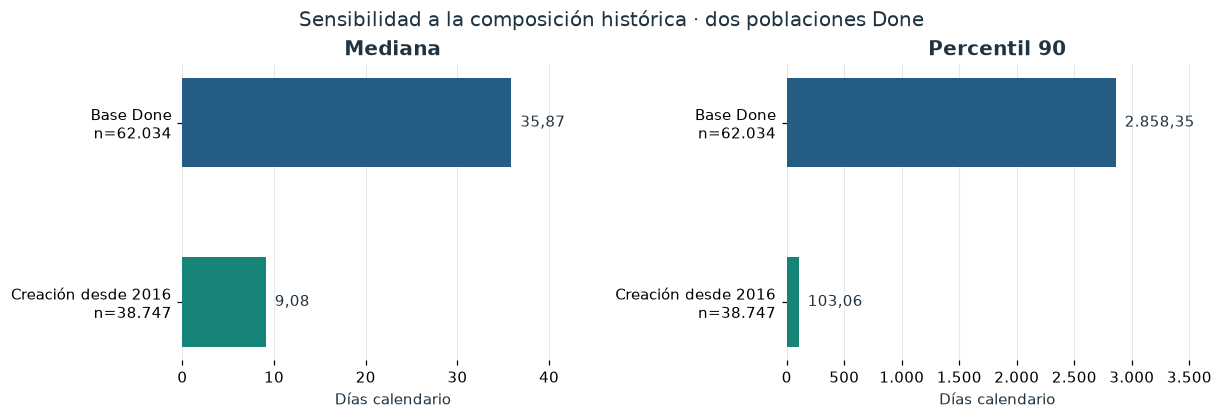

In [7]:
done = b.loc[b.grupo.eq("Done")].copy()
datos_temporales = pd.concat([
    done.assign(escenario="Base Done"),
    done.assign(escenario="Creación desde 2016", segundos=done.segundos.where(done.creacion.ge("2016-01-01"))),
], ignore_index=True)
temporal = resumen_tiempos(datos_temporales, ["escenario"])
validar_cuantiles(datos_temporales, ["escenario"], temporal, nombre="Escenarios temporales: cuantiles independientes")
mostrar(temporal[["escenario", "poblacion", "elegibles", "excluidos", "mediana_dias", "p90_dias"]]
        .rename(columns={"escenario": "Escenario", "poblacion": "Base Done", "elegibles": "Elegibles",
                         "excluidos": "Excluidos", "mediana_dias": "Mediana (días)", "p90_dias": "P90 (días)"}))
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
grafico_temporal = temporal.set_index("escenario").loc[["Base Done", "Creación desde 2016"]]
etiquetas_temporales = [f"{nombre}\nn={numero_es(fila.elegibles)}" for nombre, fila in grafico_temporal.iterrows()]
for ax, campo, titulo in zip(ejes, ["mediana_dias", "p90_dias"], ["Mediana", "Percentil 90"]):
    barras = ax.barh(etiquetas_temporales, grafico_temporal[campo], color=[PALETA["azul"], PALETA["verde"]], height=0.5)
    ax.invert_yaxis()
    ax.bar_label(barras, labels=[numero_es(v, 2) for v in grafico_temporal[campo]], padding=6)
    ax.set(title=titulo, xlabel="Días calendario", xlim=(0, grafico_temporal[campo].max() * 1.28))
    eje_numerico(ax); ax.grid(axis="x")
fig.suptitle("Sensibilidad a la composición histórica · dos poblaciones Done", fontsize=13)
plt.show(); plt.close(fig)

### Evolución de los tiempos por cohorte de creación

Se calculan cohortes anuales y mensuales para conciliar todos los grupos de la consulta C; se publican sólo los 17 años y se grafica el resumen anual. Los cuantiles consideran exclusivamente `Done` elegibles dentro de cada cohorte, mientras el denominador de tamaño es toda la cohorte.

Se informan por separado los tickets sin fecha de resolución y los no elegibles `Done`. Los primeros no equivalen a todos los excluidos. Las cohortes de los extremos son parciales; además, un año calendario completo **no garantiza seguimiento completo**. Los cuantiles de resoluciones observadas no corrigen censura: en cohortes recientes pueden favorecer los casos rápidos.

In [8]:
cohortes_datos, filas_cohortes = [], []
for nivel, periodos in [("Anual", b.creacion.dt.strftime("%Y-01-01")),
                        ("Mensual", b.creacion.dt.strftime("%Y-%m-01"))]:
    datos = b.assign(nivel=nivel, periodo=periodos, segundos=b.segundos_done)
    cohortes_datos.append(datos)
    r = resumen_tiempos(datos, ["nivel", "periodo"])
    r = r.rename(columns={"poblacion": "cohorte", "elegibles": "done_elegibles", "excluidos": "no_elegibles_done"})
    sin_fecha = datos.groupby(["nivel", "periodo"], observed=True).resolucion.apply(lambda s: s.isna().sum())
    r["sin_fecha_resolucion"] = [int(sin_fecha.loc[(nivel, p)]) for p in r.periodo]
    principios = pd.to_datetime(r.periodo, utc=True)
    finales = principios + (pd.offsets.YearEnd(0) if nivel == "Anual" else pd.offsets.MonthEnd(0))
    r["periodo_parcial"] = ((principios < inicio.normalize()) | (finales > corte.normalize())).astype(int)
    r["dias_desde_fin_periodo"] = (corte.normalize() - finales).dt.days
    filas_cohortes.append(r)
datos_cohortes = pd.concat(cohortes_datos, ignore_index=True)
cohortes = pd.concat(filas_cohortes, ignore_index=True)
conciliar("C", cohortes.drop(columns="p90_dias"), ["nivel", "periodo"])
validar_cuantiles(datos_cohortes, ["nivel", "periodo"], cohortes, nombre="Cohortes: cuantiles independientes")
anual = cohortes.loc[cohortes.nivel.eq("Anual")].copy()
anual["Año"] = anual.periodo.str[:4].astype(int)
mostrar(anual[["Año", "cohorte", "done_elegibles", "sin_fecha_resolucion", "periodo_parcial", "mediana_dias", "p90_dias"]]
        .rename(columns={"cohorte": "Cohorte", "done_elegibles": "Done elegibles", "sin_fecha_resolucion": "Sin fecha resolución",
                         "periodo_parcial": "Parcial (1=sí)", "mediana_dias": "Mediana (días)", "p90_dias": "P90 (días)"}))

Año,Cohorte,Done elegibles,Sin fecha resolución,Parcial (1=sí),Mediana (días),P90 (días)
2.007,457,457,0,1,"4.007,93","4.116,13"
2.008,1.103,1.102,0,0,"3.696,08","3.814,99"
2.009,2.157,2.157,0,0,"3.291,17","3.449,30"
2.010,3.133,3.133,0,0,"2.966,35","3.107,36"
2.011,2.966,2.966,0,0,"2.627,09","2.751,97"
2.012,3.071,3.071,0,0,"2.253,51","2.375,20"
2.013,2.442,2.442,0,0,"1.858,23","2.007,28"
2.014,2.845,2.842,0,0,"1.483,70","1.645,96"
2.015,5.543,5.117,0,0,"222,95","1.236,05"
2.016,7.053,6.526,0,0,"18,68","536,72"


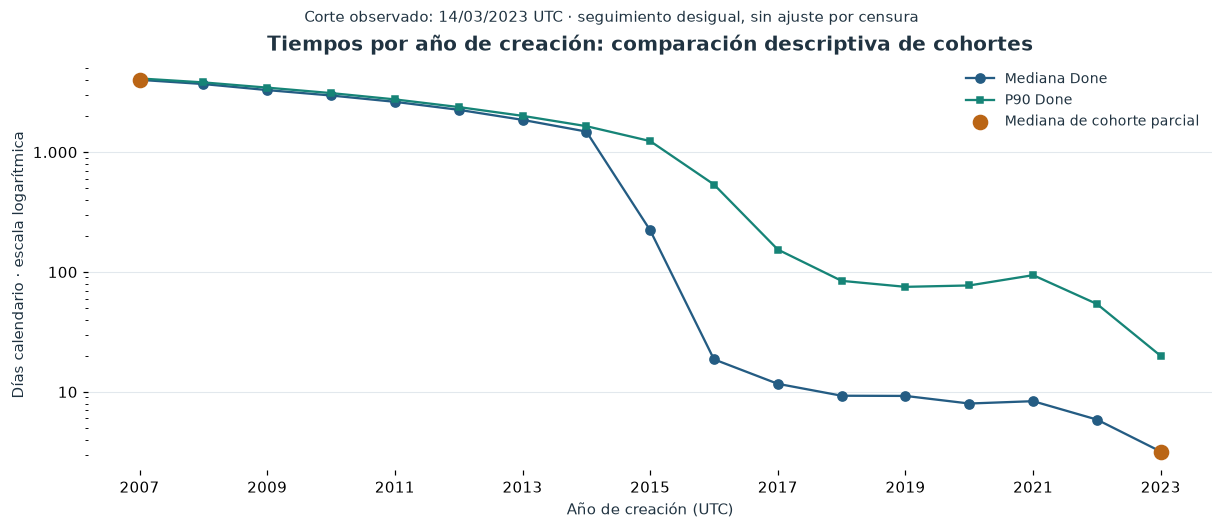

**Lectura.** Los tiempos observados difieren mucho entre cohortes antiguas y recientes. La escala logarítmica permite mostrar todos los años sin eliminar extremos; distancias iguales representan razones iguales. La tendencia no demuestra una mejora del servicio: faltan ajuste por mezcla de casos, reglas históricas y seguimiento comparable.

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.7), layout="constrained")
ax.plot(anual["Año"], anual.mediana_dias, color=PALETA["azul"], marker="o", label="Mediana Done")
ax.plot(anual["Año"], anual.p90_dias, color=PALETA["verde"], marker="s", markersize=4, label="P90 Done")
parciales = anual.periodo_parcial.eq(1)
ax.scatter(anual.loc[parciales, "Año"], anual.loc[parciales, "mediana_dias"],
           color=PALETA["naranja"], s=85, zorder=4, label="Mediana de cohorte parcial")
ax.set_yscale("log")
ax.set(title="Tiempos por año de creación: comparación descriptiva de cohortes",
       xlabel="Año de creación (UTC)", ylabel="Días calendario · escala logarítmica")
ax.set_xticks(anual["Año"].iloc[::2]); eje_numerico(ax, "y")
ax.grid(axis="y", which="major"); ax.legend(frameon=False, fontsize=9)
fig.suptitle(f"Corte observado: {corte:%d/%m/%Y} UTC · seguimiento desigual, sin ajuste por censura", fontsize=10)
plt.show(); plt.close(fig)
display(Markdown(
    "**Lectura.** Los tiempos observados difieren mucho entre cohortes antiguas y recientes. "
    "La escala logarítmica permite mostrar todos los años sin eliminar extremos; distancias iguales representan "
    "razones iguales. La tendencia no demuestra una mejora del servicio: faltan ajuste por mezcla de casos, "
    "reglas históricas y seguimiento comparable."
))

## 5. Análisis por prioridad

### Mediana y P90 de Done por prioridad

Se conserva `unknown` como categoría independiente. El tamaño `n` es el número de `Done` elegibles, no todos los tickets de esa prioridad. La tabla informa población y excluidos. El gráfico une mediana y P90 de cada grupo: **no son intervalos de confianza**.

Prioridad,Done,Elegibles,Excluidos,Mediana (días),P90 (días)
Blocker,616,616,0,"3,77","58,13"
High,4.092,4.092,0,"5,04","56,98"
Highest,1.932,1.932,0,"3,77","43,19"
Low,477,477,0,"9,02","121,11"
Lowest,80,80,0,"8,01","58,03"
Medium,22.423,22.423,0,"9,69","129,83"
unknown,32.414,32.414,0,"1.548,28","3.201,27"


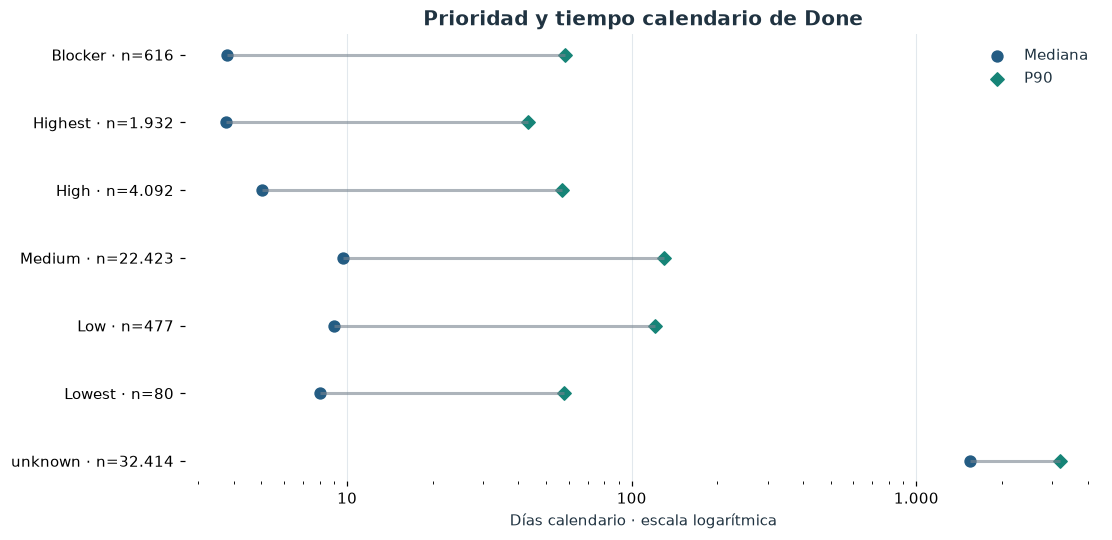

In [10]:
por_prioridad = resumen_tiempos(done, ["prioridad"])
conciliar("B", por_prioridad, ["prioridad"])
validar_cuantiles(done, ["prioridad"], por_prioridad, nombre="Prioridades: cuantiles independientes")
mostrar(por_prioridad[["prioridad", "poblacion", "elegibles", "excluidos", "mediana_dias", "p90_dias"]]
        .rename(columns={"prioridad": "Prioridad", "poblacion": "Done", "elegibles": "Elegibles",
                         "excluidos": "Excluidos", "mediana_dias": "Mediana (días)", "p90_dias": "P90 (días)"}))
fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
orden_prioridades = ["Blocker", "Highest", "High", "Medium", "Low", "Lowest", "unknown"]
gp = por_prioridad.set_index("prioridad").loc[orden_prioridades]
y = np.arange(len(gp))
ax.hlines(y, gp.mediana_dias, gp.p90_dias, color=PALETA["gris"], alpha=0.6, linewidth=2)
ax.scatter(gp.mediana_dias, y, color=PALETA["azul"], s=50, label="Mediana")
ax.scatter(gp.p90_dias, y, color=PALETA["verde"], marker="D", s=38, label="P90")
ax.set_yticks(y, [f"{p} · n={numero_es(gp.loc[p, 'elegibles'])}" for p in gp.index])
ax.invert_yaxis(); ax.set_xscale("log")
ax.set(title="Prioridad y tiempo calendario de Done", xlabel="Días calendario · escala logarítmica")
eje_numerico(ax); ax.grid(axis="x"); ax.legend(frameon=False, loc="upper right")
plt.show(); plt.close(fig)

### Comparación por tipo y tamaño de muestra

Se calculan y validan **todas las combinaciones observadas de prioridad y tipo**. Para publicar una vista legible, el mapa muestra los cinco tipos con más `Done` elegibles; la selección es por volumen, no por resultados favorables. Las combinaciones restantes siguen en el cálculo y la validación.

Cada celda incluye mediana en días y `n`; un asterisco marca `n < 30`, umbral editorial de atención, **no una regla de significación estadística**. «—» representa una combinación sin elegibles, no duración cero. El color es lineal hasta un día y logarítmico después. Se muestra también una tabla compacta de grupos pequeños, seleccionados por menor `n` y orden alfabético, sin registros individuales. `Subtask` y `Sub-task` permanecen separados.

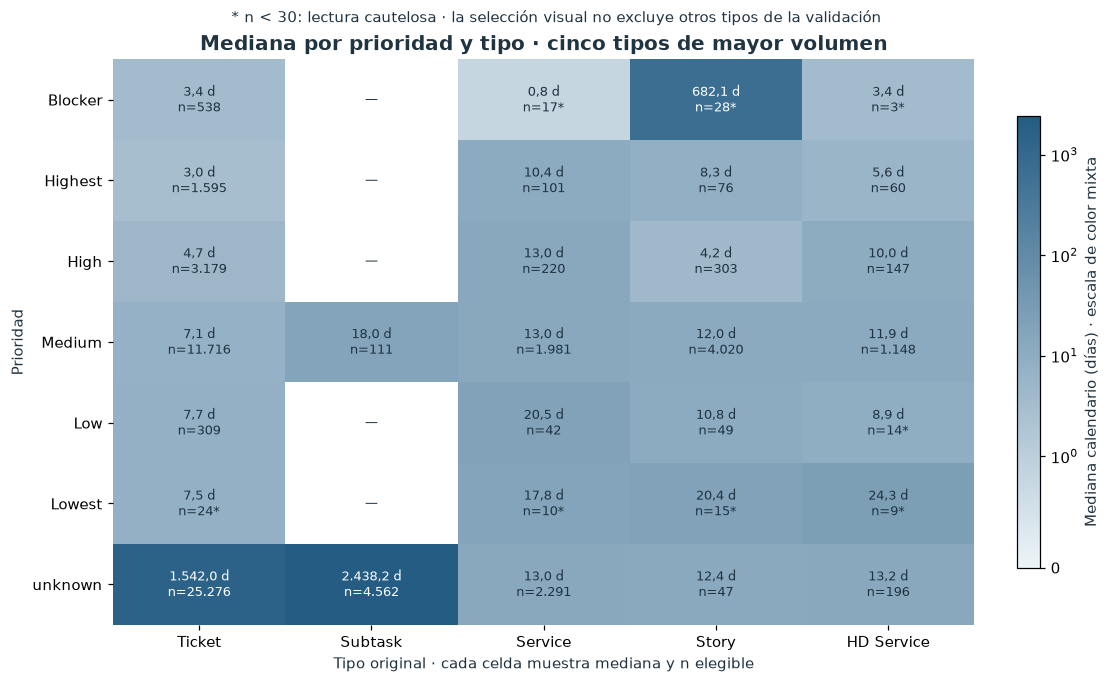

Prioridad,Tipo,n,Mediana (días),P90 (días)
Blocker,Sub-task,1,"6,03","6,03"
High,Bug,1,"18,11","18,11"
Low,Epic,1,"260,66","260,66"
Low,Sprint Summary,1,"13,01","13,01"
Lowest,Project,1,"6,68","6,68"
unknown,Assistance,1,"21,75","21,75"
Blocker,Retrospective,2,"1.636,61","1.669,17"
High,Epic,2,"656,79","723,21"


**Cobertura:** 78 combinaciones calculadas; 39 tienen n < 30. Las diferencias pueden reflejar antigüedad, tipo o proyecto. No demuestran que la prioridad cause una demora ni que un grupo sea más eficiente. Grupos con un solo caso no caracterizan una distribución estable.

In [11]:
por_tipo = resumen_tiempos(done, ["prioridad", "tipo"])
conciliar("B_TIPO", por_tipo, ["prioridad", "tipo"])
validar_cuantiles(done, ["prioridad", "tipo"], por_tipo, nombre="Prioridad y tipo: cuantiles independientes")
tipos_mostrados = por_tipo.groupby("tipo").elegibles.sum().sort_values(ascending=False).head(5).index
matriz = por_tipo.pivot(index="prioridad", columns="tipo", values="mediana_dias").reindex(
    index=orden_prioridades, columns=tipos_mostrados)
matriz_n = por_tipo.pivot(index="prioridad", columns="tipo", values="elegibles").reindex_like(matriz)
cmap = LinearSegmentedColormap.from_list("helpdesk_azul", ["#EDF4F8", PALETA["azul"]])
normalizacion = SymLogNorm(linthresh=1, vmin=0, vmax=float(np.nanmax(matriz.to_numpy())))
fig, ax = plt.subplots(figsize=(10, 6.1), layout="constrained")
im = ax.imshow(np.ma.masked_invalid(matriz.to_numpy()), cmap=cmap, norm=normalizacion, aspect="auto")
for i in range(len(matriz)):
    for j in range(len(matriz.columns)):
        valor, n = matriz.iloc[i, j], matriz_n.iloc[i, j]
        texto = "—" if pd.isna(valor) else f"{numero_es(valor, 1)} d\nn={numero_es(n)}{'*' if n < 30 else ''}"
        ax.text(j, i, texto, ha="center", va="center", fontsize=8.5,
                color="white" if pd.notna(valor) and normalizacion(valor) > 0.58 else PALETA["texto"])
ax.set_xticks(np.arange(len(matriz.columns)), matriz.columns)
ax.set_yticks(np.arange(len(matriz)), matriz.index)
ax.set(title="Mediana por prioridad y tipo · cinco tipos de mayor volumen",
       xlabel="Tipo original · cada celda muestra mediana y n elegible", ylabel="Prioridad")
fig.colorbar(im, ax=ax, shrink=0.8, label="Mediana calendario (días) · escala de color mixta")
fig.suptitle("* n < 30: lectura cautelosa · la selección visual no excluye otros tipos de la validación", fontsize=10)
plt.show(); plt.close(fig)
pequenos = por_tipo.loc[por_tipo.elegibles.lt(30)].sort_values(["elegibles", "prioridad", "tipo"])
mostrar(pequenos[["prioridad", "tipo", "elegibles", "mediana_dias", "p90_dias"]].head(8)
        .rename(columns={"prioridad": "Prioridad", "tipo": "Tipo", "elegibles": "n",
                         "mediana_dias": "Mediana (días)", "p90_dias": "P90 (días)"}))
display(Markdown(
    f"**Cobertura:** {len(por_tipo)} combinaciones calculadas; {len(pequenos)} tienen n < 30. "
    "Las diferencias pueden reflejar antigüedad, tipo o proyecto. No demuestran que la prioridad cause una demora "
    "ni que un grupo sea más eficiente. Grupos con un solo caso no caracterizan una distribución estable."
))

## 6. Análisis de reaperturas

### Agregados, eventos y denominadores

- **Ticket con visita agregada:** `wfe_reopened > 0`; proporción entre tickets con agregado conocido.
- **Ticket con evento:** al menos un evento con coincidencia exacta `field = status` y `value = reopened`; proporción entre tickets con historial.
- **Volumen:** suma de visitas o número de eventos. Un ticket puede contribuir varias veces al volumen y una sola vez a la proporción de afectados.

El historial se preagrupa antes del enlace 1:1 para no multiplicar tickets. Se separan cohortes anteriores/posteriores al inicio de eventos sin asumir que la segunda esté completa. Una entrada a `reopened` no verifica por sí sola un cierre previo válido.

In [12]:
historial = e.assign(es_reopened=(e.field.eq("status") & e.value.eq("reopened")).fillna(False).astype(int))
historial = historial.groupby("issueid").agg(eventos_total=("id", "size"), eventos_reopened=("es_reopened", "sum"))
j = b[["id", "prioridad", "creacion"]].copy()
j["wfe_reopened"] = pd.to_numeric(t.wfe_reopened, errors="raise")
j = j.join(historial, on="id", validate="one_to_one")
j["cobertura"] = np.where(j.creacion.lt(inicio_historial), "Creación anterior al historial", "Creación desde inicio historial")
j["comparable"] = j.eventos_total.notna() & j.wfe_reopened.notna()
j["delta"] = (j.wfe_reopened - j.eventos_reopened).where(j.comparable)
filas_reapertura = []
for cobertura, g in [*j.groupby("cobertura"), ("Todos", j)]:
    visitas = int(g.wfe_reopened.sum())
    numerador = int(g.wfe_reopened.gt(0).sum())
    con_historial = int(g.eventos_total.notna().sum())
    n_evento = int(g.eventos_reopened.gt(0).sum())
    filas_reapertura.append({
        "cobertura": cobertura, "tickets": len(g), "con_historial": con_historial,
        "agregado_null": int(g.wfe_reopened.isna().sum()), "tickets_wfe_reopened": numerador,
        "visitas_agregadas": visitas, "tickets_evento_reopened": n_evento,
        "eventos_reopened": int(g.eventos_reopened.sum()), "comparables": int(g.comparable.sum()),
        "discrepantes": int((g.comparable & g.delta.ne(0)).sum()),
        "pct_wfe": 100 * numerador / len(g), "pct_evento_con_historial": 100 * n_evento / con_historial,
    })
reaperturas_cobertura = pd.DataFrame(filas_reapertura)
conciliar("D", reaperturas_cobertura, ["cobertura"])
total_reapertura = reaperturas_cobertura.set_index("cobertura").loc["Todos"]
mostrar(pd.DataFrame([
    {"Indicador": "Tickets con visita agregada", "Numerador": int(total_reapertura.tickets_wfe_reopened),
     "Denominador": int(j.wfe_reopened.notna().sum()), "Porcentaje (%)": 100*j.wfe_reopened.gt(0).sum()/j.wfe_reopened.notna().sum()},
    {"Indicador": "Tickets con evento reopened", "Numerador": int(total_reapertura.tickets_evento_reopened),
     "Denominador": int(total_reapertura.con_historial), "Porcentaje (%)": total_reapertura.pct_evento_con_historial},
]), decimales=4)
mostrar(reaperturas_cobertura[["cobertura", "tickets", "con_historial", "visitas_agregadas", "eventos_reopened", "discrepantes"]]
        .rename(columns={"cobertura": "Cobertura", "tickets": "Tickets", "con_historial": "Con historial",
                         "visitas_agregadas": "Visitas", "eventos_reopened": "Eventos reopened", "discrepantes": "Discrepantes"}))

Indicador,Numerador,Denominador,Porcentaje (%)
Tickets con visita agregada,2.123,66.691,"3,1833"
Tickets con evento reopened,2.123,66.650,"3,1853"


Cobertura,Tickets,Con historial,Visitas,Eventos reopened,Discrepantes
Creación anterior al historial,20.222,20.221,534,534,0
Creación desde inicio historial,46.469,46.429,1.830,1.791,39
Todos,66.691,66.650,2.364,2.325,39


### Prioridad: volumen y proporción responden preguntas distintas

No se filtra por `Done`, antigüedad o calidad. El denominador por prioridad son sus tickets con agregado conocido. Los conteos por prioridad se contrastan con la tabla del informe final y con una segunda agregación directa del CSV; los eventos se cuentan independientemente del agregado de origen.

Prioridad,Tickets,Denominador conocido,Con reapertura,Visitas,Porcentaje (%)
Blocker,656,656,15,17,2.286585
High,4.554,4.554,166,190,3.645147
Highest,2.084,2.084,85,93,4.078695
Low,560,560,27,46,4.821429
Lowest,84,84,4,4,4.761905
Medium,24.788,24.788,542,610,2.186542
unknown,33.965,33.965,1.284,1.404,3.780362


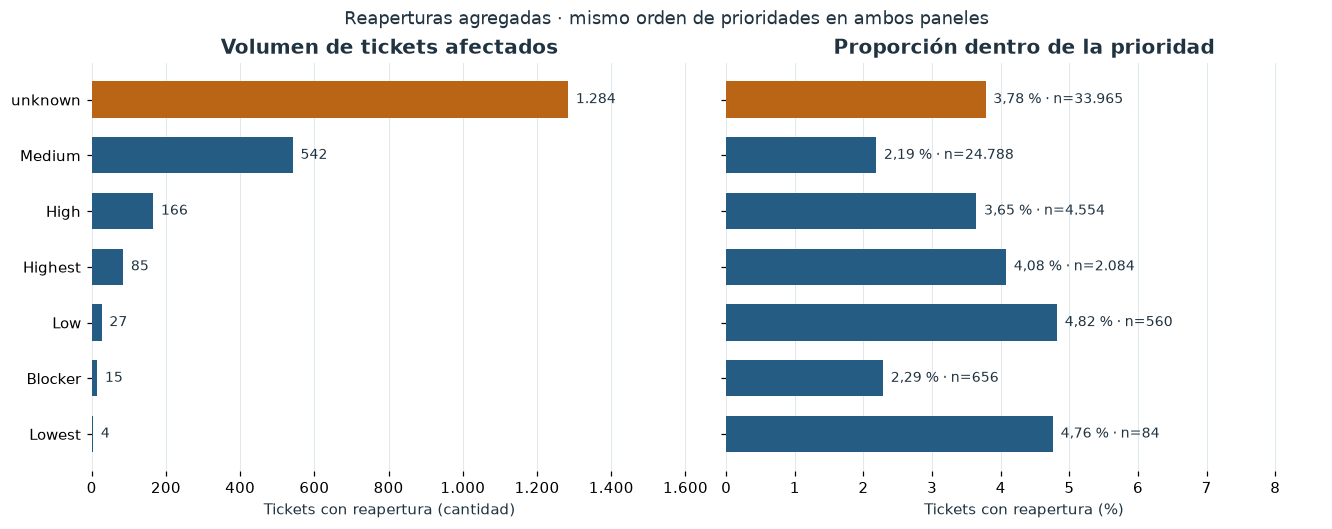

In [13]:
reaperturas_prioridad = j.assign(afectado=j.wfe_reopened.gt(0)).groupby("prioridad").agg(
    tickets=("id", "size"), conocidos=("wfe_reopened", "count"), afectados=("afectado", "sum"), visitas=("wfe_reopened", "sum"))
reaperturas_prioridad["porcentaje"] = 100 * reaperturas_prioridad.afectados / reaperturas_prioridad.conocidos
independiente = t.assign(visitas=pd.to_numeric(t.wfe_reopened), afectado=pd.to_numeric(t.wfe_reopened).gt(0)).groupby("issue_priority").agg(
    conocidos=("visitas", "count"), afectados=("afectado", "sum"), visitas=("visitas", "sum"))
verificar("Reaperturas por prioridad", np.array_equal(reaperturas_prioridad[independiente.columns].sort_index(), independiente.sort_index()),
          "Agregaciones independientes; suma de numeradores y visitas")
texto_final = REFERENCIAS[2].read_text(encoding="utf-8")
seccion_final = texto_final.split("### 5.4.", 1)[1].split("### 5.5.", 1)[0]
lineas_final = [[v.strip() for v in linea.strip("|").split("|")] for linea in seccion_final.splitlines()
                if linea.startswith("|")]
ref_prioridad = pd.DataFrame(lineas_final[2:-1], columns=lineas_final[0]).set_index("Prioridad")
def entero_documentado(valor):
    return int(valor.replace(".", ""))
for prioridad, fila in reaperturas_prioridad.iterrows():
    ref = ref_prioridad.loc[prioridad]
    if (int(fila.conocidos), int(fila.afectados), int(fila.visitas)) != tuple(entero_documentado(ref.iloc[k]) for k in [0, 1, 3]):
        raise AssertionError("Discrepancia con el informe final en reaperturas por prioridad.")
verificar("Reaperturas: informe final", True, "Siete prioridades; denominadores, afectados y visitas")
verificar("Reaperturas: presencia", np.array_equal(j.wfe_reopened.gt(0).to_numpy(dtype=bool),
          j.eventos_reopened.fillna(0).gt(0).to_numpy(dtype=bool)), "Coincidencia de tickets afectados entre ambas fuentes")
mostrar(reaperturas_prioridad.reset_index().rename(columns={"prioridad": "Prioridad", "tickets": "Tickets",
        "conocidos": "Denominador conocido", "afectados": "Con reapertura", "visitas": "Visitas", "porcentaje": "Porcentaje (%)"}))

rp = reaperturas_prioridad.sort_values("afectados", ascending=False)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.7), layout="constrained", sharey=True)
colores = [PALETA["naranja"] if p == "unknown" else PALETA["azul"] for p in rp.index]
for ax, campo, titulo, unidad in zip(ejes, ["afectados", "porcentaje"], ["Volumen de tickets afectados", "Proporción dentro de la prioridad"],
                                    ["Tickets con reapertura (cantidad)", "Tickets con reapertura (%)"]):
    barras = ax.barh(rp.index, rp[campo], color=colores, height=0.65)
    etiquetas = [numero_es(v) for v in rp[campo]] if campo == "afectados" else [
        f"{numero_es(v, 2)} % · n={numero_es(rp.loc[p, 'conocidos'])}" for p, v in rp[campo].items()]
    ax.bar_label(barras, labels=etiquetas, padding=5, fontsize=9)
    ax.set(title=titulo, xlabel=unidad, xlim=(0, rp[campo].max() * (1.25 if campo == "afectados" else 1.8)))
    eje_numerico(ax); ax.grid(axis="x")
ejes[0].invert_yaxis()
fig.suptitle("Reaperturas agregadas · mismo orden de prioridades en ambos paneles", fontsize=12)
plt.show(); plt.close(fig)

### Examen de las discrepancias, sin publicar casos individuales

Se calcula `delta = visitas agregadas − eventos reopened` sólo entre comparables. Se inspeccionan todos los tickets discrepantes en memoria y se verifica la muestra de 20 casos publicada en SQL. Las salidas se agrupan por patrón y prioridad, sin IDs, proyectos o usuarios.

Un delta positivo o negativo expresa una diferencia de conteo. No permite determinar cuál fuente es correcta ni atribuir la diferencia únicamente a la cobertura.

In [14]:
discrepancias = j.loc[j.comparable & j.delta.ne(0)].copy()
muestra_discrepancias = discrepancias.assign(delta_abs=lambda d: d.delta.abs(), id_num=lambda d: d.id.map(int)).sort_values(
    ["delta_abs", "id_num"], ascending=[False, True]).head(20)
comparacion_discrepancias = muestra_discrepancias[["id", "cobertura", "wfe_reopened", "eventos_reopened", "eventos_total"]].copy()
comparacion_discrepancias["id"] = comparacion_discrepancias.id.map(int)
conciliar("D_DIFERENCIAS", comparacion_discrepancias, ["id"])
patrones = discrepancias.groupby(["wfe_reopened", "eventos_reopened", "delta"]).size().reset_index(name="Tickets")
mostrar(patrones.rename(columns={"wfe_reopened": "Visitas agregadas", "eventos_reopened": "Eventos reopened", "delta": "Diferencia"}))
mostrar(discrepancias.groupby("prioridad").agg(Tickets=("id", "size"), Diferencia_neta=("delta", "sum")).reset_index()
        .rename(columns={"prioridad": "Prioridad"}))
verificar("Discrepancias: balance", len(discrepancias) == int(total_reapertura.discrepantes)
          and discrepancias.delta.sum() == j.wfe_reopened.sum() - j.eventos_reopened.sum(),
          "Todos los casos; balance firmado, no suma de valores absolutos")
positivos = int(discrepancias.delta.gt(0).sum())
negativos = int(discrepancias.delta.lt(0).sum())
display(Markdown(
    f"**Resultado:** {len(discrepancias)} tickets discrepantes; {positivos} con más visitas agregadas y "
    f"{negativos} con más eventos. La diferencia neta es {numero_es(discrepancias.delta.sum())}, mientras "
    f"la suma absoluta es {numero_es(discrepancias.delta.abs().sum())}. No son cantidades intercambiables.\n\n"
    "**Lectura operativa.** `unknown` concentra el mayor volumen afectado; `Low` tiene una proporción mayor "
    "que `Medium`, con bases distintas. Revisar causas de retorno requiere confirmar cierres previos y comparar "
    "tipos, proyectos y seguimiento equivalentes. Un cero observado no acredita ausencia histórica de reaperturas."
))

Visitas agregadas,Eventos reopened,Diferencia,Tickets
1,"2,00",-1.0,1
2,"1,00",1.0,27
3,"1,00",2.0,2
3,"2,00",1.0,6
4,"3,00",1.0,3


Prioridad,Tickets,Diferencia_neta
High,1,1.0
Highest,1,1.0
Medium,15,15.0
unknown,22,22.0


**Resultado:** 39 tickets discrepantes; 38 con más visitas agregadas y 1 con más eventos. La diferencia neta es 39, mientras la suma absoluta es 41. No son cantidades intercambiables.

**Lectura operativa.** `unknown` concentra el mayor volumen afectado; `Low` tiene una proporción mayor que `Medium`, con bases distintas. Revisar causas de retorno requiere confirmar cierres previos y comparar tipos, proyectos y seguimiento equivalentes. Un cero observado no acredita ausencia histórica de reaperturas.

## 7. Tiempos por estado

### Estructura larga: una fila por ticket y estado

`melt` transforma las columnas `wf_*` en filas; las visitas `wfe_*` se colocan en el mismo orden de estados y tickets. Se verifican **todos los valores y parejas** contra la estructura ancha. `wf_total_time` no se trata como un estado.

Se conserva el texto original de duración para cálculos `Decimal` exactos y una columna numérica para cuantiles. No se reemplazan nulos ni se recortan negativos. La estructura contiene 20 filas por ticket, no 20 tickets nuevos. Las únicas salidas son resúmenes.

In [15]:
largo = t[["id", *[f"wf_{s}" for s in ESTADOS]]].melt(
    id_vars="id", var_name="estado", value_name="duracion_original")
largo["estado"] = largo.estado.str.removeprefix("wf_").astype("category")
largo["segundos"] = pd.to_numeric(largo.duracion_original, errors="raise").astype(float)
largo["visitas"] = pd.concat([pd.to_numeric(t[f"wfe_{s}"], errors="raise") for s in ESTADOS], ignore_index=True).astype("Int64")
verificar("Estructura larga: grano", len(largo) == len(t) * len(ESTADOS)
          and not largo.duplicated(["id", "estado"]).any(), "Una pareja única ticket–estado")
for posicion, estado in enumerate(ESTADOS):
    bloque = largo.iloc[posicion * len(t):(posicion + 1) * len(t)]
    correcto = (bloque.id.reset_index(drop=True).equals(t.id.reset_index(drop=True))
                and bloque.duracion_original.reset_index(drop=True).equals(t[f"wf_{estado}"].reset_index(drop=True))
                and np.array_equal(bloque.visitas.to_numpy(), pd.to_numeric(t[f"wfe_{estado}"]).to_numpy()))
    if not correcto:
        raise AssertionError("Discrepancia de duración o visitas al construir la estructura larga.")
verificar("Estructura larga: valores", True, f"{len(largo)} duraciones y {len(largo)} visitas contrastadas")
largo["no_negativo"] = largo.segundos.where(largo.segundos.ge(0))
largo["promedio_visita"] = (largo.segundos / largo.visitas.where(largo.visitas.gt(0))).where(largo.segundos.ge(0)).astype(float)
filas_estados, visitas_estados = [], []
with localcontext() as contexto:
    contexto.prec = 50
    for estado, g in largo.groupby("estado", observed=True):
        exactos = g.duracion_original.dropna().map(Decimal)
        no_negativos = g.no_negativo.dropna()
        visita_elegible = g.promedio_visita.dropna()
        filas_estados.append({
            "estado": estado, "tickets": len(g), "observados": int(g.segundos.notna().sum()),
            "nulos": int(g.segundos.isna().sum()), "positivos": int(g.segundos.gt(0).sum()),
            "ceros": int(g.segundos.eq(0).sum()), "negativos": int(g.segundos.lt(0).sum()),
            "suma_firmada_seg": sum(exactos, Decimal(0)),
            "suma_positiva_seg": sum((v for v in exactos if v > 0), Decimal(0)),
            "elegibles_por_visita": len(visita_elegible),
            "duracion_sin_visitas_validas": int((g.segundos.notna() & (g.visitas.isna() | g.visitas.le(0))).sum()),
            "mediana_no_neg_seg": no_negativos.median(), "p90_no_neg_seg": no_negativos.quantile(0.9),
            "mediana_firmada_seg": g.segundos.median(), "p90_firmada_seg": g.segundos.quantile(0.9),
            "mediana_promedio_visita_seg": visita_elegible.median(),
        })
        visitas_estados.append({"estado": estado, "tickets_recorrido": int(g.visitas.gt(0).sum()),
                               "visitas_total": int(g.visitas.sum()), "elegibles": len(no_negativos)})
estados = pd.DataFrame(filas_estados)
conciliar("F", estados, ["estado"])
volumen_estados = pd.DataFrame(visitas_estados)
estados = estados.merge(volumen_estados, on="estado", validate="one_to_one")
estados["mediana_dias"] = estados.mediana_no_neg_seg / 86400
estados["p90_dias"] = estados.p90_no_neg_seg / 86400
validar_cuantiles(largo, ["estado"], estados, valor="no_negativo", mediana="mediana_no_neg_seg",
                  p90="p90_no_neg_seg", nombre="Estados: cuantiles no negativos independientes")
validar_cuantiles(largo, ["estado"], estados, valor="segundos", mediana="mediana_firmada_seg",
                  p90="p90_firmada_seg", nombre="Estados: cuantiles firmados independientes")
verificar("Estados: volumen y visitas", all(
    int(estados.set_index("estado").loc[s, "tickets_recorrido"]) == int(pd.to_numeric(t[f"wfe_{s}"]).gt(0).sum())
    and int(estados.set_index("estado").loc[s, "visitas_total"]) == int(pd.to_numeric(t[f"wfe_{s}"]).sum())
    for s in ESTADOS), "20 estados; tickets recorridos y suma de visitas desde el archivo ancho")
tabla_estados = estados.sort_values("mediana_dias", ascending=False)
mostrar(tabla_estados[["estado", "tickets_recorrido", "visitas_total", "elegibles", "nulos", "negativos", "mediana_dias", "p90_dias"]]
        .rename(columns={"estado": "Estado", "tickets_recorrido": "Tickets recorridos", "visitas_total": "Visitas",
                         "elegibles": "n no negativo", "nulos": "Nulos", "negativos": "Negativos",
                         "mediana_dias": "Mediana (días)", "p90_dias": "P90 (días)"}), decimales=6)

Estado,Tickets recorridos,Visitas,n no negativo,Nulos,Negativos,Mediana (días),P90 (días)
pending_deployment,1.413,1.723,1.413,65.278,0,"11,997419","88,982558"
validation,2.961,4.153,2.961,63.730,0,"10,179382","65,240243"
waiting,19.704,27.191,19.704,46.987,0,"6,902668","47,219400"
testing_monitoring,290,354,290,66.401,0,"5,989057","33,913407"
resolved_under_monitoring,1.931,2.165,1.931,64.760,0,"4,336965","28,010752"
to_do,785,1.013,780,65.906,5,"3,803911","79,287256"
monitoring,518,585,518,66.173,0,"2,905822","30,926878"
in_review,77,88,77,66.614,0,"2,881331","51,125424"
pending_customer_approval,254,314,254,66.437,0,"1,983295","15,604514"
deployment,135,169,135,66.556,0,"1,103681","41,647550"


### Tiempo típico y volumen de recorrido

El eje horizontal cuenta tickets con **visitas > 0**, incluidos quienes tienen duración negativa. El vertical muestra la mediana entre duraciones **conocidas y no negativas**: sus poblaciones no son idénticas y se informan en la tabla. Los ejes son logarítmicos porque hay diferencias de varios órdenes de magnitud; todos los estados se mantienen en la figura.

El naranja indica estados que contienen algún valor negativo, sin quitar esas filas del dataset. Sólo se rotulan algunos puntos para evitar saturación; la tabla conserva los 20 estados. Ni la mediana acumulada ni su suma representan horas trabajadas por agentes.

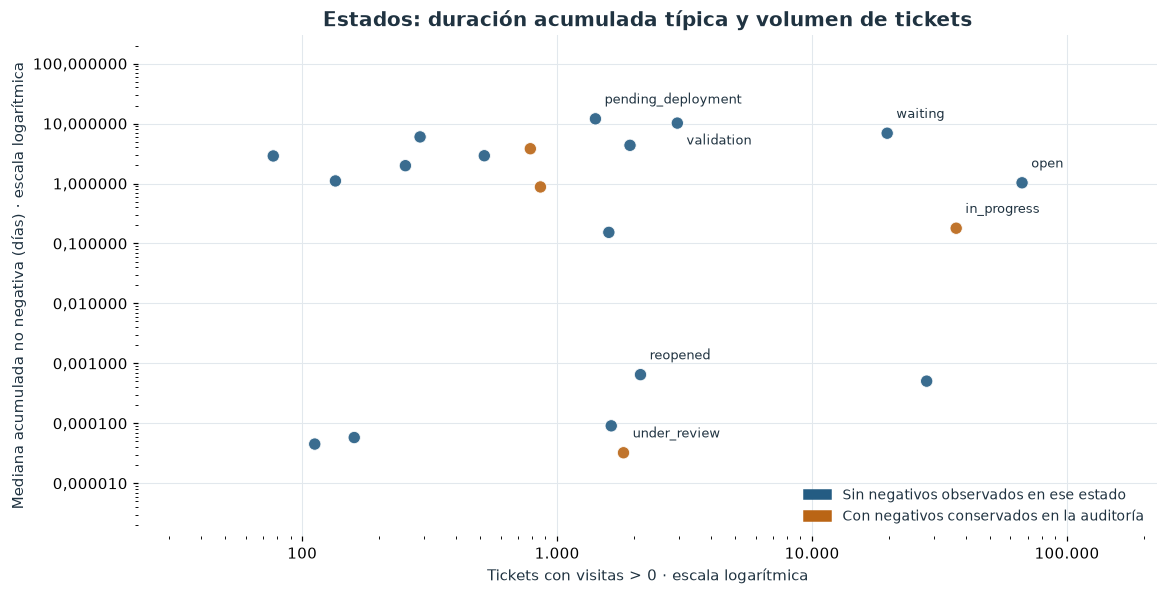

**Lectura:** `pending_deployment` tiene la mayor mediana no negativa (12,00 días; n=1.413), mientras `open` reúne la mayor suma positiva. Son rankings distintos. Las esperas, visitas repetidas, reglas del flujo y cobertura influyen en estas magnitudes; no demuestran un cuello de botella. `duración / visitas` es un promedio por ticket y estado, no una duración de visita reconstruida ni una media global ponderada de todas las visitas.

In [16]:
fig, ax = plt.subplots(figsize=(10.5, 5.3), layout="constrained")
colores_estado = np.where(estados.negativos.gt(0), PALETA["naranja"], PALETA["azul"])
ax.scatter(estados.tickets_recorrido, estados.mediana_dias, c=colores_estado, s=65, alpha=0.9,
           edgecolors="white", linewidths=0.6)
rotulados = {"open", "in_progress", "waiting", "validation", "pending_deployment", "reopened", "under_review"}
for fila in estados.itertuples():
    if fila.estado in rotulados:
        desplazamiento = (6, -14) if fila.estado == "validation" else (6, 10)
        ax.annotate(fila.estado, (fila.tickets_recorrido, fila.mediana_dias),
                    xytext=desplazamiento, textcoords="offset points", fontsize=8.5)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set(title="Estados: duración acumulada típica y volumen de tickets",
       xlabel="Tickets con visitas > 0 · escala logarítmica",
       ylabel="Mediana acumulada no negativa (días) · escala logarítmica")
eje_numerico(ax); eje_numerico(ax, "y", 6); ax.grid(which="major")
ax.margins(x=0.18, y=0.25)
ax.legend(handles=[Patch(color=PALETA["azul"], label="Sin negativos observados en ese estado"),
                   Patch(color=PALETA["naranja"], label="Con negativos conservados en la auditoría")],
          loc="lower right", frameon=False, fontsize=9)
plt.show(); plt.close(fig)
mas_tiempo = estados.loc[estados.mediana_dias.idxmax()]
mas_suma = estados.loc[estados.suma_positiva_seg.map(float).idxmax()]
display(Markdown(
    f"**Lectura:** `{mas_tiempo.estado}` tiene la mayor mediana no negativa "
    f"({numero_es(mas_tiempo.mediana_dias, 2)} días; n={numero_es(mas_tiempo.elegibles)}), "
    f"mientras `{mas_suma.estado}` reúne la mayor suma positiva. Son rankings distintos. "
    "Las esperas, visitas repetidas, reglas del flujo y cobertura influyen en estas magnitudes; no demuestran "
    "un cuello de botella. `duración / visitas` es un promedio por ticket y estado, no una duración de visita "
    "reconstruida ni una media global ponderada de todas las visitas."
))

## 8. Calidad y sensibilidad

### Anomalías conservadas y solapamientos

Se utilizan los flags existentes. `dq_has_problem` agrupa condiciones y no incluye toda ausencia opcional o falta de historial. Los 450 tickets señalados no son una suma de categorías excluyentes. La comparación de duración se refiere a `wf_total_time` frente a `ended − started`, no al tiempo calendario hasta resolución.

Se comprueba la combinación completa de flags contra Q_FLAGS y el número de tickets con alguna duración negativa desde la estructura larga. Un control técnico superado no garantiza interpretación operativa correcta.

In [17]:
columnas_flags = ["dq_has_problem", "dq_negative_duration", "dq_duration_mismatch"]
flags = t[columnas_flags].copy()
verificar("Flags: dominio", flags.isin(["True", "False"]).all().all(), "Valores True/False conocidos")
flags_bool = flags.eq("True")
q_flags = b.assign(**{c: flags[c] for c in columnas_flags}).groupby(columnas_flags, dropna=False).agg(
    tickets=("id", "size"), elegibles_calendario=("segundos", "count"), elegibles_done=("segundos_done", "count")).reset_index()
conciliar("Q_FLAGS", q_flags, columnas_flags)
mostrar(q_flags.rename(columns={"dq_has_problem": "Alguna anomalía", "dq_negative_duration": "Duración negativa",
        "dq_duration_mismatch": "Discrepancia", "tickets": "Tickets", "elegibles_calendario": "Calendario elegibles",
        "elegibles_done": "Done elegibles"}))
ids_negativos = set(largo.loc[largo.segundos.lt(0), "id"])
verificar("Negativos: tickets", ids_negativos == set(t.loc[flags_bool.dq_negative_duration, "id"]),
          "La unión de wf_* negativos coincide con el flag del archivo")
solapamiento = int((flags_bool.dq_negative_duration & flags_bool.dq_duration_mismatch).sum())
display(Markdown(
    f"**Resultado:** {numero_es(flags_bool.dq_has_problem.sum())} tickets con alguna anomalía; "
    f"{numero_es(flags_bool.dq_negative_duration.sum())} con negativos; "
    f"{numero_es(flags_bool.dq_duration_mismatch.sum())} con discrepancia; "
    f"**{numero_es(solapamiento)} con ambas condiciones**. No deben sumarse como tickets únicos. "
    "Las anomalías se conservan, se documentan y se someten a sensibilidad; no se eliminan automáticamente."
))

Alguna anomalía,Duración negativa,Discrepancia,Tickets,Calendario elegibles,Done elegibles
False,False,False,66.241,65.388,61.647
True,False,False,65,65,3
True,False,True,330,330,329
True,True,False,11,11,11
True,True,True,44,44,44


**Resultado:** 450 tickets con alguna anomalía; 55 con negativos; 374 con discrepancia; **44 con ambas condiciones**. No deben sumarse como tickets únicos. Las anomalías se conservan, se documentan y se someten a sensibilidad; no se eliminan automáticamente.

### Escenarios de sensibilidad: base, fechas y filtros de workflow

Todos los escenarios parten de los mismos tickets `Done`. Se enmascara la duración para los no incluidos, por lo que **excluidos = población Done original − elegibles del escenario**. No se altera ninguna fila de origen. Los escenarios no se acumulan entre sí ni se escoge automáticamente el que dé un tiempo menor.

El escenario de fechas revisa flags específicos de las fechas usadas; los filtros de workflow responden a otra definición. Una anomalía de workflow no implica que creación → resolución sea un intervalo negativo.

In [18]:
mascaras = {
    "Base Done": pd.Series(True, index=done.index),
    "Creación desde 2016": done.creacion.ge("2016-01-01"),
    "Fechas sin flags específicos": t.loc[done.index, ["dq_invalid_issue_created", "dq_invalid_issue_resolution_date",
        "dq_naive_issue_created", "dq_naive_issue_resolution_date", "dq_resolution_before_creation"]].eq("False").all(axis=1),
    "Sin dq_has_problem (sensibilidad)": t.loc[done.index, "dq_has_problem"].eq("False"),
    "Sin negativos/mismatch workflow": t.loc[done.index, ["dq_negative_duration", "dq_duration_mismatch"]].eq("False").all(axis=1),
}
datos_sensibilidad = pd.concat([done.assign(escenario=nombre, segundos=done.segundos.where(mascara))
                               for nombre, mascara in mascaras.items()], ignore_index=True)
sensibilidad = resumen_tiempos(datos_sensibilidad, ["escenario"])
conciliar("Q", sensibilidad, ["escenario"])
validar_cuantiles(datos_sensibilidad, ["escenario"], sensibilidad, nombre="Sensibilidad: cuantiles independientes")
verificar("Sensibilidad: base y exclusiones", sensibilidad.poblacion.eq(len(done)).all()
          and sensibilidad.elegibles.add(sensibilidad.excluidos).eq(len(done)).all(),
          "Cinco escenarios con el mismo denominador original")
verificar("Escenarios temporales y Q", np.allclose(
    temporal.set_index("escenario").sort_index()[["elegibles", "excluidos", "mediana_seg", "p90_seg"]],
    sensibilidad.set_index("escenario").loc[temporal.escenario].sort_index()[["elegibles", "excluidos", "mediana_seg", "p90_seg"]],
    atol=0.0001, rtol=1e-12), "La selección de 2016 usa la misma definición en ambos apartados")
mostrar(sensibilidad[["escenario", "poblacion", "elegibles", "excluidos", "mediana_dias", "p90_dias"]]
        .rename(columns={"escenario": "Escenario", "poblacion": "Base Done", "elegibles": "Elegibles", "excluidos": "Excluidos",
                         "mediana_dias": "Mediana (días)", "p90_dias": "P90 (días)"}))
display(Markdown(
    "**Interpretación.** La selección temporal modifica los cuantiles mucho más que excluir los flags actuales. "
    "Esto señala sensibilidad a la composición histórica, no demuestra qué fechas sean erróneas ni qué población "
    "represente el desempeño real. Mantener la base completa junto a cada escenario hace visible el coste de la exclusión."
))

Escenario,Base Done,Elegibles,Excluidos,Mediana (días),P90 (días)
Base Done,62.034,62.034,0,"35,87","2.858,35"
Creación desde 2016,62.034,38.747,23.287,"9,08","103,06"
Fechas sin flags específicos,62.034,62.034,0,"35,87","2.858,35"
Sin dq_has_problem (sensibilidad),62.034,61.647,387,"35,97","2.862,36"
Sin negativos/mismatch workflow,62.034,61.650,384,"35,96","2.862,33"


**Interpretación.** La selección temporal modifica los cuantiles mucho más que excluir los flags actuales. Esto señala sensibilidad a la composición histórica, no demuestra qué fechas sean erróneas ni qué población represente el desempeño real. Mantener la base completa junto a cada escenario hace visible el coste de la exclusión.

## 9. Hallazgos y conclusiones

### Resultados de esta ejecución

Las cifras siguientes se toman de los cálculos del notebook. Los gráficos comparten esas mismas poblaciones y tablas; el redondeo es sólo de presentación.

In [19]:
base = sensibilidad.set_index("escenario").loc["Base Done"]
desde_2016 = sensibilidad.set_index("escenario").loc["Creación desde 2016"]
sin_flags = sensibilidad.set_index("escenario").loc["Sin dq_has_problem (sensibilidad)"]
mostrar(pd.DataFrame([
    {"Hallazgo": "Done, base completa", "Resultado": f"Mediana {numero_es(base.mediana_dias, 2)} d; P90 {numero_es(base.p90_dias, 2)} d",
     "Población": f"n={numero_es(base.elegibles)}"},
    {"Hallazgo": "Done, creaciones desde 2016", "Resultado": f"Mediana {numero_es(desde_2016.mediana_dias, 2)} d; P90 {numero_es(desde_2016.p90_dias, 2)} d",
     "Población": f"n={numero_es(desde_2016.elegibles)}; excluidos={numero_es(desde_2016.excluidos)}"},
    {"Hallazgo": "Reaperturas agregadas", "Resultado": f"{numero_es(total_reapertura.tickets_wfe_reopened)} tickets; {numero_es(total_reapertura.visitas_agregadas)} visitas",
     "Población": f"{numero_es(j.wfe_reopened.notna().sum())} agregados conocidos"},
    {"Hallazgo": "Diferencia entre fuentes", "Resultado": f"{numero_es(total_reapertura.eventos_reopened)} eventos; {len(discrepancias)} tickets discrepantes",
     "Población": f"{numero_es(total_reapertura.comparables)} comparables"},
    {"Hallazgo": "Mayor mediana por estado", "Resultado": f"{mas_tiempo.estado}: {numero_es(mas_tiempo.mediana_dias, 2)} d",
     "Población": f"n no negativo={numero_es(mas_tiempo.elegibles)}"},
    {"Hallazgo": "Excluir anomalías no equivale a corregir", "Resultado": f"Mediana Done sin flags: {numero_es(sin_flags.mediana_dias, 2)} d",
     "Población": f"Excluidos={numero_es(sin_flags.excluidos)} de {numero_es(base.poblacion)} Done"},
]))

Hallazgo,Resultado,Población
"Done, base completa","Mediana 35,87 d; P90 2.858,35 d",n=62.034
"Done, creaciones desde 2016","Mediana 9,08 d; P90 103,06 d",n=38.747; excluidos=23.287
Reaperturas agregadas,2.123 tickets; 2.364 visitas,66.691 agregados conocidos
Diferencia entre fuentes,2.325 eventos; 39 tickets discrepantes,66.650 comparables
Mayor mediana por estado,"pending_deployment: 12,00 d",n no negativo=1.413
Excluir anomalías no equivale a corregir,"Mediana Done sin flags: 35,97 d",Excluidos=387 de 62.034 Done


### Limitaciones, recomendaciones y relación con Power BI

| Evidencia | Límite de interpretación | Recomendación y presentación en Power BI |
|---|---|---|
| Cola extensa y sensibilidad a 2016 | Mezcla histórica y semántica de fechas sin confirmar | Mostrar base y sensibilidades con n, excluidos y corte; investigar registros antiguos sin borrarlos |
| Diferencias por prioridad y tipo | No hay ajuste por proyecto, antigüedad o complejidad; grupos pequeños | Mantener `unknown`, cantidades y filtros de tipo; marcar grupos pequeños sin afirmar significación |
| Reaperturas con dos fuentes | Eventos incompletos y cierre previo no reconstruido | Separar tickets afectados, visitas y eventos; mostrar denominadores y discrepancias |
| Tiempo acumulado y volumen por estado | Visitas repetidas, espera y poblaciones distintas | Mostrar n recorrido y n elegible junto a mediana/P90; revisar dependencias antes de declarar cuellos de botella |
| Anomalías y filtros de calidad | Flags solapados y controles semánticos incompletos | Mantener auditoría visible; informar la unión de problemas y el efecto de cada exclusión |

Los resultados se relacionan con **Análisis operativo**, **Tiempos por Estado** y **Calidad de Datos**, mientras **Resumen General** necesita conservar contexto de población. No se ha modificado el dashboard ni auditado sus medidas DAX. Para evitar doble conteo, las medidas de tickets parten de `bi.vw_tickets`; eventos y estados tienen sus propias granularidades, según [el modelo analítico](../reports/bi_data_model.md).

Las cohortes recientes pueden estar censuradas y los cuantiles sólo describen resoluciones observadas. Las comparaciones no prueban mejoras causales. `Done` no mide satisfacción, los acumulados no equivalen a horas trabajadas y no se dispone de objetivos SLA ni calendario laboral validado. Las recomendaciones son propuestas; no se implantaron ni evaluaron cambios empresariales reales.

### Registro de validaciones y discrepancias

Se verifica la integridad de archivos al finalizar. La tabla presenta controles de grupos y de métricas por separado, en bloques pequeños. La conciliación compara CSV con los informes SQL existentes: no certifica el estado actual de la base.

Las discrepancias existentes de reaperturas, las anomalías y la diferencia de cobertura documental se conservan. Si aparece una diferencia numérica con las referencias, la celda correspondiente falla y exige investigar; no se cambian los informes para obtener una aprobación artificial.

In [20]:
verificar("Integridad de fuentes", all(huella(ruta) == huellas_antes[ruta] for ruta in protegidos),
          "Dos CSV y tres informes idénticos antes y después")
tabla_controles = pd.DataFrame(controles)
for inicio_bloque in range(0, len(tabla_controles), 12):
    mostrar(tabla_controles.iloc[inicio_bloque:inicio_bloque + 12])
print(f"{len(controles)} controles superados. Sin discrepancias numéricas con las referencias contrastadas.")
print("Se conservaron las anomalías y discrepancias de origen; siete gráficos calculados sin registros individuales publicados.")

Control,Estado,Alcance
Claves,SUPERADA,"IDs no nulos, únicos; historial sin huérfanos"
Dimensiones,SUPERADA,Contrato documentado: 66.691 × 102 y 257.508 × 28
SQL S: grupos,SUPERADA,1 grupos; sin publicar claves individuales
SQL S: métricas,SUPERADA,5 campos en todos los grupos
SQL A: grupos,SUPERADA,3 grupos; sin publicar claves individuales
SQL A: métricas,SUPERADA,7 campos en todos los grupos
Resoluciones: cuantiles independientes,SUPERADA,"3 grupos; agregación, Series.quantile y NumPy"
SQL A_EXCLUSIONES: grupos,SUPERADA,3 grupos; sin publicar claves individuales
SQL A_EXCLUSIONES: métricas,SUPERADA,1 campos en todos los grupos
Histogramas completos,SUPERADA,Todos los elegibles aparecen en los intervalos


Control,Estado,Alcance
Escenarios temporales: cuantiles independientes,SUPERADA,"2 grupos; agregación, Series.quantile y NumPy"
SQL C: grupos,SUPERADA,209 grupos; sin publicar claves individuales
SQL C: métricas,SUPERADA,9 campos en todos los grupos
Cohortes: cuantiles independientes,SUPERADA,"209 grupos; agregación, Series.quantile y NumPy"
SQL B: grupos,SUPERADA,7 grupos; sin publicar claves individuales
SQL B: métricas,SUPERADA,7 campos en todos los grupos
Prioridades: cuantiles independientes,SUPERADA,"7 grupos; agregación, Series.quantile y NumPy"
SQL B_TIPO: grupos,SUPERADA,78 grupos; sin publicar claves individuales
SQL B_TIPO: métricas,SUPERADA,7 campos en todos los grupos
Prioridad y tipo: cuantiles independientes,SUPERADA,"78 grupos; agregación, Series.quantile y NumPy"


Control,Estado,Alcance
Reaperturas por prioridad,SUPERADA,Agregaciones independientes; suma de numeradores y visitas
Reaperturas: informe final,SUPERADA,"Siete prioridades; denominadores, afectados y visitas"
Reaperturas: presencia,SUPERADA,Coincidencia de tickets afectados entre ambas fuentes
SQL D_DIFERENCIAS: grupos,SUPERADA,20 grupos; sin publicar claves individuales
SQL D_DIFERENCIAS: métricas,SUPERADA,4 campos en todos los grupos
Discrepancias: balance,SUPERADA,"Todos los casos; balance firmado, no suma de valores absolutos"
Estructura larga: grano,SUPERADA,Una pareja única ticket–estado
Estructura larga: valores,SUPERADA,1333820 duraciones y 1333820 visitas contrastadas
SQL F: grupos,SUPERADA,20 grupos; sin publicar claves individuales
SQL F: métricas,SUPERADA,15 campos en todos los grupos


Control,Estado,Alcance
Estados: volumen y visitas,SUPERADA,20 estados; tickets recorridos y suma de visitas desde el archivo ancho
Flags: dominio,SUPERADA,Valores True/False conocidos
SQL Q_FLAGS: grupos,SUPERADA,5 grupos; sin publicar claves individuales
SQL Q_FLAGS: métricas,SUPERADA,3 campos en todos los grupos
Negativos: tickets,SUPERADA,La unión de wf_* negativos coincide con el flag del archivo
SQL Q: grupos,SUPERADA,5 grupos; sin publicar claves individuales
SQL Q: métricas,SUPERADA,7 campos en todos los grupos
Sensibilidad: cuantiles independientes,SUPERADA,"5 grupos; agregación, Series.quantile y NumPy"
Sensibilidad: base y exclusiones,SUPERADA,Cinco escenarios con el mismo denominador original
Escenarios temporales y Q,SUPERADA,La selección de 2016 usa la misma definición en ambos apartados


47 controles superados. Sin discrepancias numéricas con las referencias contrastadas.
Se conservaron las anomalías y discrepancias de origen; siete gráficos calculados sin registros individuales publicados.


### Conclusión

El análisis avanzado aporta una lectura de distribuciones, composición y sensibilidad que complementa el volumen exploratorio. La mediana, el P90, las reaperturas y las duraciones por estado responden a preguntas diferentes y sólo son interpretables con su población y cobertura.

La trazabilidad permite distinguir una diferencia numérica de cálculo de una discrepancia existente en el origen. Los hallazgos justifican investigar clasificación, registros antiguos, retornos y esperas; no justifican corregir fechas, imputar ausencias ni eliminar casos automáticamente.

Para reproducir esta entrega, consulta [la guía de notebooks](README.md), selecciona `.venv`, reinicia el kernel y ejecuta todo. Los PNG embebidos y las tablas compactas permiten revisar los resultados en GitHub sin ejecutar Python.